## Step 1: Environment Setup

In [1]:
# Mounting Drive, making src/ importable, and installing neurokit2
from google.colab import drive
drive.mount('/content/drive')

import os, sys
PROJECT = '/content/drive/MyDrive/ecg-project'
OUT = f'{PROJECT}/data_processed'
sys.path.append(f'{PROJECT}/src')
!pip install -q neurokit2

Mounted at /content/drive
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 688.9/688.9 kB 31.3 MB/s eta 0:00:00


## Step 2: Load Processed Data

In [2]:
# Loading the processed train/val/test splits and metadata saved in data_pipeline.ipynb
import numpy as np, pandas as pd
import data

meta = pd.read_csv(f'{OUT}/metadata.csv', index_col='ecg_id')
splits = {s: data.load_split(s) for s in ['train', 'val', 'test']}
LEADS = ['I', 'II', 'III', 'AVR', 'AVL', 'AVF', 'V1', 'V2', 'V3', 'V4', 'V5', 'V6']

for s, (X, y) in splits.items():
    print(f'{s:5s}: {X.shape} | abnormal rate {y.mean():.2f}')

train: (17084, 1000, 12) | abnormal rate 0.58
val  : (2146, 1000, 12) | abnormal rate 0.57
test : (2158, 1000, 12) | abnormal rate 0.58


## Step 3: Extracting Clinical ECG Features

In [3]:
# Extracting rhythm features (lead II) and per-lead beat morphology (R, S, ST, T amplitudes) for every ECG
import neurokit2 as nk
from scipy.stats import skew, kurtosis
from joblib import Parallel, delayed

FS = 100

def extract_features(ecg):
    f = {}
    try:
        _, info = nk.ecg_peaks(ecg[:, 1], sampling_rate=FS)
        r_all = np.asarray(info['ECG_R_Peaks'])
    except Exception:
        r_all = np.array([], dtype=int)

    # Rhythm: heart rate and variability from R-R intervals
    rr = np.diff(r_all) / FS
    f['hr'] = 60 / rr.mean() if len(rr) else np.nan
    f['rr_std'] = rr.std() if len(rr) else np.nan
    f['rmssd'] = np.sqrt(np.mean(np.diff(rr) ** 2)) if len(rr) > 1 else np.nan
    f['n_beats'] = len(r_all)

    # Morphology: median beat per lead, from 250 ms before to 450 ms after each R peak
    r = r_all[(r_all >= 25) & (r_all <= len(ecg) - 45)]
    tmpl = np.median(np.stack([ecg[i - 25:i + 45] for i in r]), axis=0) if len(r) else None

    for j, lead in enumerate(LEADS):
        x = ecg[:, j]
        f[f'{lead}_std'], f[f'{lead}_skew'], f[f'{lead}_kurt'] = x.std(), skew(x), kurtosis(x)
        if tmpl is None:
            f.update({f'{lead}_{k}': np.nan for k in ['r', 's', 'st', 't']})
            continue
        t = tmpl[:, j]
        base = t[5:15].mean()                                  # PR segment as the baseline
        f[f'{lead}_r'] = t[22:29].max() - base                 # R-wave amplitude
        f[f'{lead}_s'] = t[25:34].min() - base                 # S-wave depth
        f[f'{lead}_st'] = t[37] - base                         # ST level, about 120 ms after R
        tw = t[45:70] - base
        f[f'{lead}_t'] = tw[np.argmax(np.abs(tw))]             # T-wave amplitude, signed
    return f

feats = {}
for s, (X, _) in splits.items():
    rows = Parallel(n_jobs=-1)(delayed(extract_features)(x) for x in X)
    feats[s] = pd.DataFrame(rows, index=meta[meta['split'] == s].index)
    feats[s].to_csv(f'{OUT}/features_{s}.csv')
    print(f'{s:5s}: {feats[s].shape} | rows with missing beats: {feats[s]["hr"].isna().mean():.1%}')

print(feats['train'][['hr', 'II_r', 'V1_st', 'V2_t']].describe().round(2))

train: (17084, 88) | rows with missing beats: 0.0%
val  : (2146, 88) | rows with missing beats: 0.0%
test : (2158, 88) | rows with missing beats: 0.0%
             hr      II_r     V1_st      V2_t
count  17080.00  17083.00  17083.00  17083.00
mean      74.11      4.32      0.34      1.21
std       16.07      2.58      0.38      1.07
min       17.62     -3.12     -7.36    -12.29
25%       63.08      2.46      0.15      0.63
50%       71.34      4.06      0.29      1.14
75%       82.29      5.84      0.46      1.75
max      175.90     24.72      8.64     10.61


## Step 4: Preparing Features and Labels

In [4]:
# Building feature tables and labels for Task A (binary) and Task B (5-class multi-label)
CLASSES = ['NORM', 'MI', 'STTC', 'CD', 'HYP']
RESULTS = f'{PROJECT}/results'

Xf = feats  # feature DataFrames per split
yb = {s: meta.loc[Xf[s].index, 'abnormal'].values for s in Xf}
ym = {s: meta.loc[Xf[s].index, CLASSES].values for s in Xf}
print({s: Xf[s].shape for s in Xf})

{'train': (17084, 88), 'val': (2146, 88), 'test': (2158, 88)}


## Step 5: Training Baseline Models (Task A)

In [5]:
# Training logistic regression and XGBoost for Normal vs Abnormal; tuning XGBoost with early stopping on validation
from sklearn.pipeline import make_pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import RobustScaler, FunctionTransformer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import roc_auc_score
from xgboost import XGBClassifier

SEED = 42

def clip5(x):
    return np.clip(x, -5, 5)

def make_xgb(pos_weight=1.0):
    return XGBClassifier(n_estimators=1000, learning_rate=0.05, max_depth=5, subsample=0.8,
                         colsample_bytree=0.8, scale_pos_weight=pos_weight, eval_metric='auc',
                         early_stopping_rounds=50, random_state=SEED, n_jobs=-1)

logreg = make_pipeline(SimpleImputer(strategy='median'), RobustScaler(),
                       FunctionTransformer(clip5), LogisticRegression(C=0.1, max_iter=2000))
logreg.fit(Xf['train'], yb['train'])

xgb = make_xgb()
xgb.fit(Xf['train'], yb['train'], eval_set=[(Xf['val'], yb['val'])], verbose=False)

models = {'LogReg': logreg, 'XGBoost': xgb}
for name, m in models.items():
    print(f"{name:8s} validation AUROC: {roc_auc_score(yb['val'], m.predict_proba(Xf['val'])[:, 1]):.3f}")
print('XGBoost stopped at tree', xgb.best_iteration)

LogReg   validation AUROC: 0.895
XGBoost  validation AUROC: 0.933
XGBoost stopped at tree 366


## Step 6: Evaluating on the Test Set (Task A)

In [6]:
# Choosing each model's decision threshold on validation (Youden's J), then evaluate once on the test set and save predictions
from sklearn.metrics import roc_curve, average_precision_score, f1_score, confusion_matrix

def youden_threshold(y, p):
    fpr, tpr, thr = roc_curve(y, p)
    return thr[np.argmax(tpr - fpr)]

def evaluate(y, p, thr):
    pred = (p >= thr).astype(int)
    tn, fp, fn, tp = confusion_matrix(y, pred).ravel()
    return {'AUROC': roc_auc_score(y, p), 'AUPRC': average_precision_score(y, p),
            'Sensitivity': tp / (tp + fn), 'Specificity': tn / (tn + fp),
            'F1': f1_score(y, pred), 'Threshold': thr}

results = {}
preds = pd.DataFrame({'y_true': yb['test']}, index=Xf['test'].index)
for name, m in models.items():
    thr = youden_threshold(yb['val'], m.predict_proba(Xf['val'])[:, 1])
    p = m.predict_proba(Xf['test'])[:, 1]
    results[name] = evaluate(yb['test'], p, thr)
    preds[f'p_{name}'] = p

res_bin = pd.DataFrame(results).T.round(3)
res_bin.to_csv(f'{RESULTS}/baseline_binary_metrics.csv')
preds.to_csv(f'{RESULTS}/preds_test_baseline_binary.csv')
res_bin

,AUROC,AUPRC,Sensitivity,Specificity,F1,Threshold
LogReg,0.885,0.924,0.747,0.882,0.815,0.583
XGBoost,0.917,0.948,0.794,0.899,0.850,0.550


## Step 7: Multi-Label Baseline (Task B)

In [7]:
# Training one XGBoost per superclass (weighted for imbalance) and report per-class and macro AUROC on test
preds_m = pd.DataFrame(index=Xf['test'].index)
auc_m = {}
for k, c in enumerate(CLASSES):
    pos = ym['train'][:, k].mean()
    m = make_xgb(pos_weight=(1 - pos) / pos)
    m.fit(Xf['train'], ym['train'][:, k], eval_set=[(Xf['val'], ym['val'][:, k])], verbose=False)
    preds_m[f'y_{c}'] = ym['test'][:, k]
    preds_m[f'p_{c}'] = m.predict_proba(Xf['test'])[:, 1]
    auc_m[c] = roc_auc_score(ym['test'][:, k], preds_m[f'p_{c}'])

auc_m['Macro'] = np.mean(list(auc_m.values()))
res_multi = pd.Series(auc_m, name='Test AUROC').round(3)
res_multi.to_csv(f'{RESULTS}/baseline_multilabel_auroc.csv')
preds_m.to_csv(f'{RESULTS}/preds_test_baseline_multilabel.csv')
res_multi

,Test AUROC
NORM,0.932
MI,0.906
STTC,0.927
CD,0.869
HYP,0.903
Macro,0.907


## Step 8: Which Features Matter?

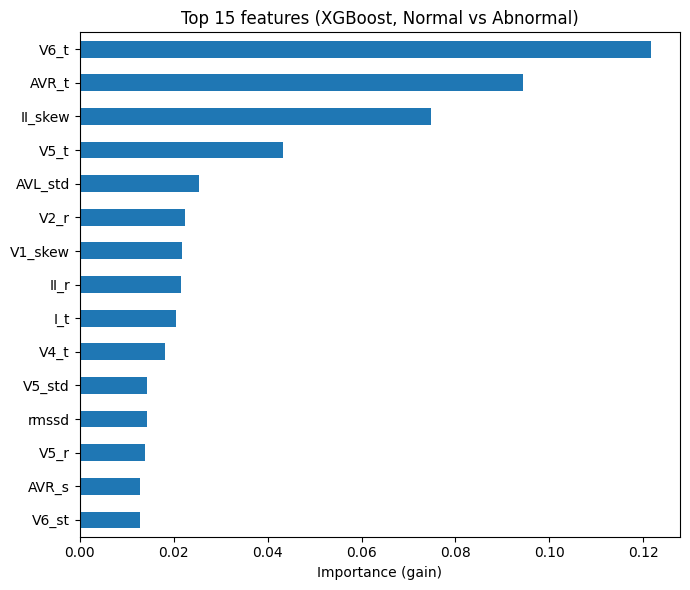

In [8]:
# Plotting the 15 most important features in the Task A XGBoost model
import matplotlib.pyplot as plt

imp = pd.Series(xgb.feature_importances_, index=Xf['train'].columns).nlargest(15).sort_values()
imp.plot(kind='barh', figsize=(7, 6), title='Top 15 features (XGBoost, Normal vs Abnormal)')
plt.xlabel('Importance (gain)')
plt.tight_layout()
plt.savefig(f'{RESULTS}/figures/baseline_feature_importance.png', dpi=150)
plt.show()